In [7]:
import pandas as pd
import os
import sys
__file__ = os.getcwd()
absolute_path = os.path.abspath(__file__)[
    : os.path.abspath(__file__).find("MAD_BTC") + len("MAD_BTC")
]
sys.path.append(absolute_path)
from src.utils.utils_df import open_dataframe

         Time    Portfolio  Buy_and_Hold  Position  \
0  2018-10-16  1000.000000    953.977884         1   
1  2018-10-31   893.991630    854.555647        -1   
2  2018-11-02   893.991630    868.959032         1   
3  2018-11-15   806.703882    785.685223        -1   
4  2018-12-21   806.703882    513.214405         1   

   Relative_Portfolio_VS_Relative_Buy&Hold  Portfolio/Buy_and_Hold  \
0                                      NaN                1.048242   
1                                -0.001790                1.046148   
2                                -0.016855                1.028808   
3                                -0.001807                1.026752   
4                                 0.346794                1.571865   

   RSI_Portfolio/Buy_and_Hold  
0                         NaN  
1                         NaN  
2                         NaN  
3                         NaN  
4                         NaN  


<Axes: >

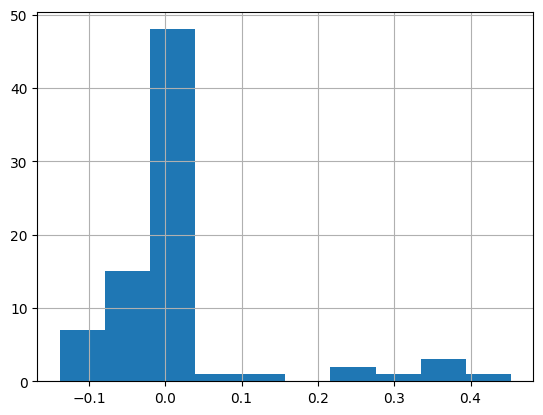

In [10]:
PATH = (
    absolute_path
    + r"\experience\BNBUSDT\binance\1d\momentum_strategy\0ab83010636d975d48474b5abee4903145a93cf60c8953c46bd62ceb65317f51\output_file.csv"
)
df = pd.read_csv(PATH)
df["Relative_Portfolio_VS_Relative_Buy&Hold"].hist()

<Axes: >

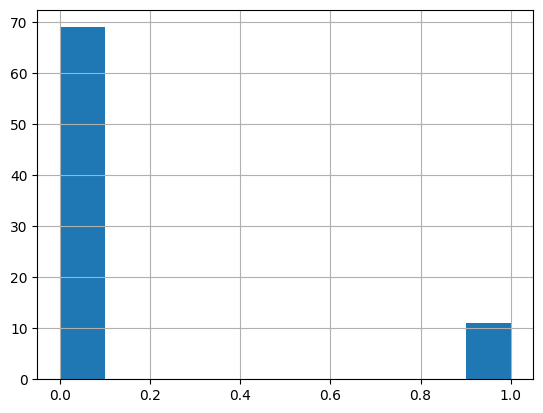

In [11]:
import numpy as np
df["binary_classification"] = np.where(df["Relative_Portfolio_VS_Relative_Buy&Hold"] > 0, 1, 0)
df["binary_classification"].hist()

In [12]:
def convert_time_iloc(dt, first, end, window_size):
    """
    Args:
        dt ():
        first ():
        end ():
        window_size ():

    Returns:
    """
    start = end - dt * window_size
    duration = start - first
    start_index = duration // dt + 1  # le +1 car on démarre à iloc[0]
    end_index = start_index + window_size
    return start_index, end_index

In [26]:
data_df = open_dataframe(absolute_path+r"\data\binance-BNBUSDT-1D.pkl")

In [35]:
df["Time"] = pd.to_datetime(df["Time"])
dt = data_df["Time"].diff().iloc[1]
window_size = 20
i = 30
end = df["Time"].iloc[i]
first = data_df["open_date"].iloc[0]
print(df["Time"])

0    2018-10-16
1    2018-10-31
2    2018-11-02
3    2018-11-15
4    2018-12-21
        ...    
75   2024-02-04
76   2024-02-05
77   2024-02-06
78   2024-02-08
79   2024-03-31
Name: Time, Length: 80, dtype: datetime64[ns]


In [34]:
print(end,'Time for the data')
print(dt)
start_index, end_index = convert_time_iloc(dt,first,end,window_size)
print(data_df[["high","low","open","open_date"]].iloc[start_index:end_index])

2020-12-19 00:00:00 Time for the data
15 days 00:00:00
       high      low     open  open_date
47  16.2760  12.0001  12.3679 2018-05-18
48  15.6666  13.9500  15.0885 2018-05-19
49  14.3995  13.6820  14.3350 2018-05-20
50  14.8005  13.7000  14.1664 2018-05-21
51  14.8500  13.6911  14.6728 2018-05-22
52  13.9299  12.2350  13.8544 2018-05-23
53  13.1947  12.1000  12.4997 2018-05-24
54  13.3789  12.5627  13.0255 2018-05-25
55  13.2830  12.6411  13.0129 2018-05-26
56  12.8000  12.2856  12.7561 2018-05-27
57  12.7500  11.6110  12.5960 2018-05-28
58  12.7000  11.6601  11.8920 2018-05-29
59  12.7927  12.1700  12.5947 2018-05-30
60  14.3020  12.3800  12.6080 2018-05-31
61  14.4670  13.7600  14.1919 2018-06-01
62  14.8820  14.0000  14.2503 2018-06-02
63  15.0254  14.2657  14.6785 2018-06-03
64  14.7430  13.5900  14.6660 2018-06-04
65  15.7110  14.1328  14.2635 2018-06-05
66  17.4767  15.2300  15.6156 2018-06-06
